# 스토리보드: Aurora 기반 뉴델리 대기질 조기경보

[English version](https://notebook.link/github/playground-for-thinker/aurora/tree/storymap/specta/?path=storyboard_en.ipynb) · [스토리 맵 (JupyterGIS)](https://notebook.link/github/playground-for-thinker/aurora/tree/storymap/specta/?path=delhi_aq_storymap_ko.jGIS) · [소스 (GitHub)](https://github.com/playground-for-thinker/aurora/tree/main/examples/delhi_air_quality)

> "오늘 밤부터 내일 아침까지 아난드 비하르 일대 AQI가 450을 넘을 것으로 예상됩니다. 창문을 닫고, 아이들의 등교 전 야외 활동을 피하세요."
>
> 이 한 줄의 메시지가 시민에게 도달하기까지, 무엇이 필요하고 Aurora가 어디서 쓰이는지를 장면별로 정리한 문서입니다.

스토리 맵(지도 위 장면별 내러티브, JupyterGIS 문서를 notebook.link에서 열기): [한국어](https://notebook.link/github/playground-for-thinker/aurora/tree/storymap/specta/?path=delhi_aq_storymap_ko.jGIS) · [English](https://notebook.link/github/playground-for-thinker/aurora/tree/storymap/specta/?path=delhi_aq_storymap_en.jGIS) · 이 스토리보드를 notebook.link에서 보기(Specta 아티클, 그래프는 브라우저에서 계산): [한국어](https://notebook.link/github/playground-for-thinker/aurora/tree/storymap/specta/?path=storyboard_ko.ipynb) · [English](https://notebook.link/github/playground-for-thinker/aurora/tree/storymap/specta/?path=storyboard_en.ipynb) · 영어 마크다운: [`STORYBOARD.md`](https://notebook.link/github/playground-for-thinker/aurora/tree/storymap/specta/?path=storyboard_en.ipynb)

관련 파일:

| 파일 | 역할 |
| - | - |
| [`delhi_aq.py`](https://github.com/playground-for-thinker/aurora/blob/main/examples/delhi_air_quality/delhi_aq.py) | 전체 파이프라인 구현(데이터 → 모델 → AQI → 메시지). CLI로도 실행 가능 |
| [`example_delhi_air_quality.ipynb`](https://github.com/playground-for-thinker/aurora/blob/main/examples/delhi_air_quality/example_delhi_air_quality.ipynb) | 스토리보드를 따라가며 실행하는 노트북 |
| [`README_kor.md`](https://github.com/playground-for-thinker/aurora/blob/main/examples/delhi_air_quality/README_kor.md) | 설치·실행 방법, 환경 변수, 바로 열어보기 링크 |
| `storymap/storyboard_{ko,en}.ipynb` | 이 문서의 notebook.link 버전(섹션별 마크다운 셀 + 그래프·표 코드 셀). `build_storyboard_notebooks.py`로 생성 |
| [`storyboard.html`](https://github.com/playground-for-thinker/aurora/blob/main/examples/delhi_air_quality/storyboard.html) | 이 문서의 단일 HTML 파일 버전(언어 전환, demo 그래프) |
| [`storymap/`](https://github.com/playground-for-thinker/aurora/tree/main/examples/delhi_air_quality/storymap) | 스토리 맵의 JupyterGIS 버전: `delhi_aq_storymap_{ko,en}.jGIS` + GeoJSON 레이어 + notebook.link 환경 파일. `build_storymap_jgis.py`로 생성, `publish_storymap_branch.sh`로 발행 |
| [`storymap.html`](https://github.com/playground-for-thinker/aurora/blob/main/examples/delhi_air_quality/storymap.html), `storymap_data.js` | 스토리 맵의 단일 HTML 파일 버전: 지도 위에서 장면별로 시간이 흐르며 한국어 ⇄ English 전환 |

---


## 0. 배경: 왜 뉴델리이고, 왜 11월인가

- 델리 NCR(수도권)은 매년 10월 말~1월에 세계 최악 수준의 미세먼지 에피소드를 겪습니다. 인접 주의 추수 후 볏짚 소각, 디왈리 폭죽, 교통·건설·발전 배출이 겹치고, 겨울철 **낮은 혼합층(경계층 높이 100~300 m)과 약한 바람**이 오염을 지표 근처에 가둡니다.
- 인도 정부는 국가 AQI(CPCB 기준)와 단계별 대응계획 **GRAP**(Graded Response Action Plan, CAQM 주관)을 운영합니다. GRAP은 AQI 구간별로 건설 중단, 차량 제한, 학교 원격수업, 재택근무 등 조치를 정해두고 있어 **"예보 → 단계 → 조치"**의 연결이 제도적으로 이미 존재합니다.
- 따라서 이 스토리보드의 핵심 질문은 "얼마나 나빠질지"가 아니라 **"언제, 어느 지역에서, 어떤 기상 조건 때문에 나빠지며, 시민은 무엇을 해야 하는가"**를 12~48시간 앞서 전달하는 것입니다.


## 1. 등장인물

| 역할 | 원하는 것 | 이 예제에서의 산출물 |
| - | - | - |
| 일반 시민 | 오늘 밤/내일 아침에 무엇을 조심해야 하는지 한 줄로 | `messages_*.json`의 `short` (푸시/SMS용) |
| 민감군(어린이·노인·호흡기 질환자, 보호자) | 구체적인 행동 지침과 시간대 | `long` 메시지의 건강 권고·확산 조건 |
| 운영자(DPCC/CAQM 담당자, 또는 서비스 운영팀) | 지점별 정점 시각, GRAP 단계 근거, 추세 | `summary_by_site.csv`, `bulletin_*.md` |
| 데이터/ML 엔지니어 | 재현 가능한 파이프라인, 로컬/클라우드 전환 | [`delhi_aq.py`](https://github.com/playground-for-thinker/aurora/blob/main/examples/delhi_air_quality/delhi_aq.py)의 `--mode local|foundry` |


## 2. 시스템 구성: Aurora가 두 번 등장한다

```
   [데이터 소스]                       [Aurora 모델]                         [델리 후처리]                  [시민]
                                                                                                                 
 CAMS 전지구 분석 (0.4°)  ─────►  Aurora 0.4° Air Pollution  ──┐                                              
  PM1/2.5/10, NO2, SO2,            12시간 간격 × 4 = 48h        │   10개 지점 보간    CPCB AQI     메시지 생성   
  O3, CO + 기상 변수               (로컬 GPU 또는 Foundry        ├─►  (아난드 비하르,  ─►  GRAP 단계  ─►  ko/en/hi ─► 푸시/SMS/
                                    "Aurora" 엔드포인트)          │    ITO, 드와르카…)    정체 진단      short/long   WhatsApp/앱
 ERA5 또는 IFS HRES T0 (0.25°) ─► Aurora 1.5                   ─┘                                              
  26개 표면 변수, 13개 기압면       6시간 × 8 + 시간별 서브스텝                                                   
                                   = 48개 시간별 예측                                                            
                                   (경계층 높이, 10 m 풍속,                                                       
                                    기온, 이슬점, 강수, 돌풍)                                                      
```

**왜 두 모델인가.** Aurora 1.5는 기상 전용 모델이라 오염물질을 예측하지 않습니다. 대신 **시간 단위**로 경계층 높이(`blh`), 풍속, 강수 같은 **확산 조건**을 줍니다. 반대로 Aurora Air Pollution은 오염물질 농도를 직접 예측하지만 12시간 간격·0.4° 해상도입니다. 두 모델을 합치면 "농도는 어느 수준인가"(Air Pollution)와 "밤 몇 시부터 정체가 시작되는가"(1.5)를 함께 말할 수 있습니다.

**"고해상도"의 의미.** 이 예제에서 고해상도는 두 가지입니다. (1) **시간 해상도**: Aurora 1.5의 `fine_lead_times=[1,…,6]`으로 1시간 간격 예측. (2) **공간 표현**: 0.4°/0.25° 격자를 델리 NCR 10개 대표 지점으로 양선형 보간. 격자 자체가 도시 내부 차이를 해소하지는 못하므로, 지점 간 차이는 주로 지역 평균의 공간 경향을 반영합니다(§6 한계 참고).

**msresearch-aurora 스킬과의 연계.** 저장소의 `msresearch-aurora/`(microsoft/vibe-kit의 Aurora 스킬)에서 세 가지를 가져옵니다. (1) 노르웨이 예제의 React 지도 프런트엔드: 이 파이프라인은 같은 JSON 스키마로 델리 NCR 타일(27.5~31.5°N, 76~80°E)을 내보내므로 `setup_region.py --name "Delhi NCR"`로 복제한 지도에서 시간 슬라이더로 바람·기온·기압(패치 후 PM2.5·AQI)을 볼 수 있습니다. (2) `validate_grid.py`, `download_era5_subset.py`, `check_divergence.py`, `validate_forecast.py` 같은 검증 유틸리티. (3) `starter-code/`의 파인튠 스타터(§7). 자세한 절차는 [`README_kor.md`](https://github.com/playground-for-thinker/aurora/blob/main/examples/delhi_air_quality/README_kor.md)의 "msresearch-aurora 스킬과의 연계"에 있습니다.

**Azure AI Foundry와의 연계.** 체크포인트는 HuggingFace `microsoft/aurora`에서 자동으로 내려받습니다. GPU가 없거나 운영 환경이라면 `--mode foundry`로 Azure AI Foundry의 **"Aurora"** (Air Pollution 포함) 및 **"Aurora-1.5"** 엔드포인트에 `aurora.foundry.submit`으로 작업을 보냅니다. Aurora-1.5 엔드포인트는 `fine_lead_times`, `saved_surf_vars`(필요한 변수만 저장), `async_upload_workers`를 지원하여 전송량과 시간을 줄입니다.


## 3. 장면별 타임라인 (예: 11월 5일 발행)

| 시각 (IST) | 장면 | 시스템에서 일어나는 일 |
| - | - | - |
| 17:30 (= 12 UTC) | **S1. 초기장 확보** | CAMS 00/12 UTC 분석, ERA5(또는 HRES T0) 06/12 UTC 다운로드. 정적 변수 pickle 로드. `Batch` 2개 구성 |
| 17:40 | **S2. 예측 실행** | Air Pollution 4스텝(+12/24/36/48 h), Aurora 1.5 8스텝 × 6 서브스텝(+1…+48 h). GPU 1장 또는 Foundry |
| 17:50 | **S3. 델리 추출·융합** | 10개 지점 보간. 12시간 농도를 시간별로 선형 보간하고, 1.5의 시간별 `blh`·풍속으로 **정체 시간대**(풍속 < 10 km/h, 혼합층 < 500 m) 표시. CPCB AQI·주 오염물질·GRAP 단계 산출 |
| 18:00 | **S4. 저녁 경보 발송** | 지점별 `short` 메시지(푸시/SMS). 예: "[대기질 경보] Anand Vihar: 최고 AQI 500 (위험), 11월 7일 05시 전후 정점 예상. 주 오염물질 PM10, PM2.5 최대 300㎍/㎥. 건강한 사람도 영향을 받습니다." |
| 18:00 | **S4b. 지도 확인** | `outputs/frontend/*.json`을 msresearch-aurora 프런트엔드에 넣어 운영자가 타일 전체의 공간 패턴(남동쪽 정체, 풍향)을 눈으로 확인 |
| 18:00 | **S5. 운영자 브리핑** | `bulletin_ko.md`: 도시 전체 헤드라인 + 지점별 상세(정점 시각, 추세, 정체 시간, GRAP 조치 안내). 운영자는 CAQM 공식 단계 발표와 대조 |
| 22:00~08:00 | **S6. 정체 구간** | 1.5가 예측한 야간 혼합층 150~300 m, 풍속 1~2 m/s 구간. 메시지에 "밤~아침에 오염이 지표 근처에 쌓이기 쉽습니다"로 반영. 민감군용 리마인더(창문 닫기, 새벽 운동 자제) 발송 가능 |
| 06:00 (다음 날) | **S7. 아침 업데이트** | 00 UTC 초기장으로 재실행(크론). 등교·출근 전 "오전 7~9시 최고치, 마스크 착용" 메시지 |
| 사후 | **S8. 검증** | CPCB/DPCC 관측(SAMEER, CPCB CCR)과 지점별 예측 비교. 편향 보정 계수 산출 → 다음 발행에 반영 |


## 4. 메시지 설계 원칙

1. **무엇(수치+범주)·언제(IST 정점 시각)·어디(지점)·어떻게(행동 1~2개)**를 160자 안에 담는다. `short`는 SMS/푸시, `long`은 앱 상세·브리핑용.
2. **범주는 CPCB 용어를 그대로** 쓴다(좋음/양호/보통/나쁨/매우 나쁨/위험). 시민이 뉴스·공식 앱에서 보는 용어와 일치해야 혼란이 없다.
3. **행동 지침은 민감군을 먼저** 호명한다(어린이·노인·임산부·호흡기 질환자).
4. **GRAP 단계는 "해당 수준"으로만 표현**한다. 실제 조치 발효는 CAQM 권한이므로 "시행될 수 있습니다"로 쓰고, 공식 공지를 확인하라고 안내한다.
5. **기상 근거를 한 문장 포함**한다("혼합층 500 m 미만·풍속 10 km/h 미만 정체 37시간"). 시민이 "왜 밤에 더 나쁜가"를 이해하면 행동 순응도가 올라간다.
6. **면책 문구 고정**: "AI 모델(Aurora) 기반 참고 정보이며 공식 경보는 CPCB/CAQM을 따르세요."
7. 언어: 힌디어(1차), 영어(2차), 그리고 운영팀용 한국어. 모든 템플릿은 [`delhi_aq.py`](https://github.com/playground-for-thinker/aurora/blob/main/examples/delhi_air_quality/delhi_aq.py)의 `HEALTH_ADVICE`, `GRAP_ADVICE`, `CATEGORY_NAMES`에 모여 있어 보건 전문가가 코드 변경 없이 문구를 검수할 수 있다.


## 5. 산출물 예시 (demo 모드)

도시 헤드라인:

> 델리 NCR 대기질 전망: 지역 중간값 최고 AQI 434 (위험), 최악 지점 Anand Vihar AQI 500 (위험), 11월 7일 05시 전후. GRAP 4단계 수준에 해당합니다.

지점 상세(`bulletin_ko.md` 일부):

> ■ Anand Vihar 대기질 예보 (11월 5일 18시 ~ 11월 7일 17시)
> - 현재 AQI 386 → 최고 AQI 500 (위험), 정점 11월 7일 05시 전후. 추세: 비슷한 수준 유지.
> - 주 오염물질: PM10. PM2.5 최대 3xx㎍/㎥, PM10 최대 5xx㎍/㎥.
> - 확산 조건: 향후 예측기간 중 37시간(야간·새벽 20시간) 동안 풍속 10 km/h 미만, 혼합층 500 m 미만의 정체 조건이 예상됩니다(최저 혼합층 약 133 m). …
> - 건강 권고: 건강한 사람도 영향을 받습니다. 가능한 한 실내에 머무르고 …
> - 행정 조치 안내: GRAP 4단계(위험+) 수준: 트럭 진입 제한, 재택근무 확대 … 당국 공지를 확인하세요.

demo 모드의 수치는 11월 전형적 에피소드를 흉내 낸 합성값이며, 실제 예측은 `--mode local` 또는 `--mode foundry`로 얻습니다.


### Anand Vihar 48시간 시계열과 지점별 요약 (브라우저에서 계산)

아래 두 셀은 이 노트북 옆의 `data/anand_vihar_hourly.json`, `data/summary_by_site.json`(스토리 맵과 같은 실행 결과)을 읽어 notebook.link의 WebAssembly Python 커널에서 그립니다. 코드는 Specta 설정으로 숨겨져 있으며 JupyterLab 보기에서 볼 수 있습니다.


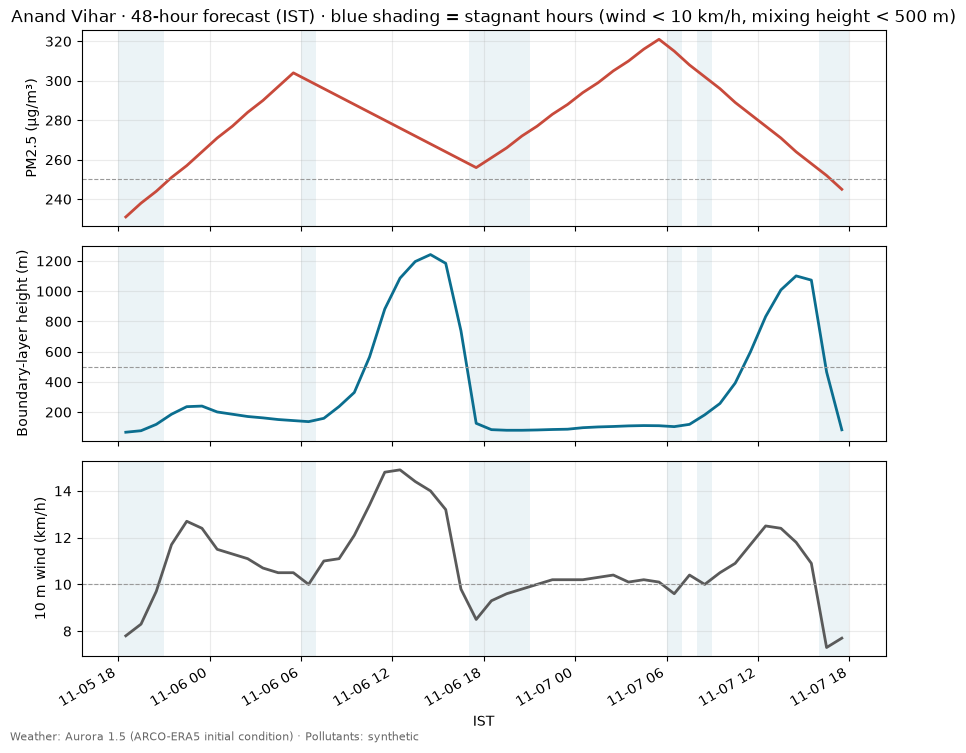

In [1]:
import json
from datetime import datetime, timedelta
from pathlib import Path

import matplotlib.pyplot as plt

d = json.loads(Path("data/anand_vihar_hourly.json").read_text(encoding="utf-8"))
ist = [datetime.fromisoformat(t) + timedelta(hours=5, minutes=30) for t in d["times_utc"]]
stag = d["stagnant"]

fig, axes = plt.subplots(3, 1, figsize=(9, 7.5), sharex=True)
panels = [("pm25", "PM2.5 (µg/m³)", "#c84a3b", 250), ("blh_m", "Boundary-layer height (m)", "#0b6e8f", 500), ("wind_kmh", "10 m wind (km/h)", "#5a5a5a", 10)]
for ax, (key, label, color, thr) in zip(axes, panels):
    ax.plot(ist, d[key], color=color, lw=2)
    ax.axhline(thr, color="#999", lw=0.8, ls="--")
    for i, s in enumerate(stag):
        if s:
            ax.axvspan(ist[i] - timedelta(minutes=30), ist[i] + timedelta(minutes=30), color="#0b6e8f", alpha=0.08, lw=0)
    ax.set_ylabel(label)
    ax.grid(alpha=0.25)
axes[0].set_title(f"{d['site']} · 48-hour forecast (IST) · blue shading = stagnant hours (wind < 10 km/h, mixing height < 500 m)")
axes[-1].set_xlabel("IST")
fig.autofmt_xdate()
prov = d.get("provenance", {})
fig.text(0.01, 0.005, f"Weather: {prov.get('meteorology', 'synthetic')} · Pollutants: {prov.get('pollutants', 'synthetic')}", fontsize=8, color="#666")
plt.tight_layout()
plt.show()


In [2]:
import json
from pathlib import Path

from IPython.display import Markdown, display

rows = json.loads(Path("data/summary_by_site.json").read_text(encoding="utf-8"))
cat_ko = {"Good": "좋음", "Satisfactory": "양호", "Moderate": "보통", "Poor": "나쁨", "Very Poor": "매우 나쁨", "Severe": "위험"}
lines = ["| 지점 | 현재 AQI | 최고 AQI | 범주 | 주 오염물질 | GRAP | 정체 h (야간) | 최저 혼합층 m | 정점 (IST) |", "| --- | ---: | ---: | --- | --- | ---: | ---: | ---: | --- |"]
for r in rows:
    lines.append(f"| {r['site']} | {r['aqi_now']} | {r['aqi_peak']} | {cat_ko.get(r['category_peak'], r['category_peak'])} | {r['dominant']} | {r['grap_stage']} | {r['stagnant_hours']} ({r['stagnant_night_hours']}) | {r['min_blh_m']} | {r['peak_time_ist']} |")
display(Markdown("\n".join(lines)))


| 지점 | 현재 AQI | 최고 AQI | 범주 | 주 오염물질 | GRAP | 정체 h (야간) | 최저 혼합층 m | 정점 (IST) |
| --- | ---: | ---: | --- | --- | ---: | ---: | ---: | --- |
| Anand Vihar | 385 | 500 | 위험 | PM10 | 4 | 12 (2) | 67 | 2025-11-07 05:30 |
| Dwarka Sector 8 | 336 | 406 | 위험 | PM2.5 | 3 | 16 (6) | 71 | 2025-11-07 05:30 |
| Gurugram Vikas Sadan | 376 | 479 | 위험 | PM10 | 4 | 15 (5) | 68 | 2025-11-07 05:30 |
| ITO | 383 | 498 | 위험 | PM10 | 4 | 13 (2) | 69 | 2025-11-07 05:30 |
| Jahangirpuri | 365 | 452 | 위험 | PM10 | 4 | 14 (5) | 75 | 2025-11-07 05:30 |
| Noida Sector 62 | 340 | 409 | 위험 | PM2.5 | 3 | 10 (1) | 64 | 2025-11-07 05:30 |
| Okhla Phase 2 | 366 | 453 | 위험 | PM10 | 4 | 11 (1) | 64 | 2025-11-07 05:30 |
| Punjabi Bagh | 346 | 415 | 위험 | PM2.5 | 3 | 14 (5) | 74 | 2025-11-07 05:30 |
| R K Puram | 335 | 405 | 위험 | PM2.5 | 3 | 13 (3) | 71 | 2025-11-07 05:30 |
| Rohini | 337 | 406 | 위험 | PM2.5 | 3 | 16 (7) | 73 | 2025-11-07 05:30 |

## 6. 한계와 책임 있는 사용

- **공간 해상도**: Air Pollution 모델은 0.4°(약 40 km)입니다. 지점 간 차이는 보간 결과이며, 교차로·공단 수준의 국지 농도는 표현하지 못합니다. 실제 서비스에서는 CPCB 관측소별 편향 보정(§3 S8)이나 CPCB 데이터로의 추가 파인튜닝이 필요합니다.
- **시간 해상도**: 시간별 농도 곡선은 12시간 예측의 선형 보간입니다. 시간별 구조의 근거는 Aurora 1.5의 기상 변수이며, 메시지에도 그렇게 표기합니다.
- **입력 데이터**: Aurora 1.5는 IFS HRES T0로 파인튜닝되었습니다. 이 예제는 접근이 쉬운 ERA5를 쓰므로 정확도가 보장되지 않습니다(공식 1.5 예제와 같은 입장). Air Pollution 모델은 CAMS 분석 전용입니다.
- **1000 hPa 가스 농도**: NO2/SO2/O3/CO는 1000 hPa 혼합비를 밀도로 환산한 값입니다. 델리(해발 약 216 m)는 1000 hPa 면보다 약간 높아 근사치입니다. AQI 판정은 사실상 PM2.5/PM10이 주도합니다.
- **운영 결정**: 이 저장소의 책임 있는 AI 문서가 명시하듯 Aurora는 연구용 모델이며, 전문가 검토 없는 운영 의사결정에 쓰여서는 안 됩니다. 메시지에는 항상 공식 경보(CPCB/CAQM)를 따르라는 문구가 포함됩니다.


## 7. 확장 로드맵

1. **불확실성**: `AuroraV1p5Ensemble` + `rollout_ensemble`로 기상 앙상블을 돌려 "정체 확률 80%" 식의 확률 표현 추가.
2. **CPCB 관측 동화/보정**: 지점별 관측-예측 잔차를 학습해 보정(간단한 선형/분위 매핑부터).
3. **파인튜닝**: `msresearch-aurora/starter-code/`(PyTorch Lightning 학습 루프, `vibe_tune_aurora.cli.train`)로 Air Pollution 모델을 인도 지역 CAMS 재분석 또는 격자화한 CPCB 관측에 파인튜닝하여 지역 편향 축소. 모델 측 요구사항(정규화 통계 등록, `strict=False` 로드)은 이 저장소의 `docs/finetuning.md`, 학습 측 가이드는 스킬의 `docs/finetuning-guide.md`.
4. **채널 연계**: `messages_hi.json`을 WhatsApp Business API, SMS 게이트웨이, 또는 델리 정부 앱 백엔드로 전달하는 작은 어댑터. 지점은 사용자의 거주 지역(핀코드)으로 매핑.
5. **자동화**: 00/12 UTC마다 `python delhi_aq.py --mode foundry --plot`을 크론으로 실행하고, 산출물을 블롭 스토리지에 적재.


## 8. 로드맵 실행 결과 (2025년 11월 5일 12 UTC 초기장)

로드맵 다섯 항목을 `delhi_aq.py --mode hybrid --members 3`로 실행했습니다. 표기 구분은 스토리 맵과 같습니다.

| 항목 | 실행 내용 | 구분 | 결과 |
| - | - | - | - |
| 1 불확실성 | 공개 ARCO-ERA5 초기장으로 `AuroraV1p5Ensemble`을 시드 3개로 실행, 멤버별 혼합층·풍속으로 정체 확률 산출 | Aurora 직접 분석 | 지점별 평균 정체 확률 0.26~0.34, 타일 평균 0.50. 결정론 1.5 예측의 야간 최저 혼합층 64~75 m |
| 2 관측 보정 | 지점별 선형 보정(관측 = a + b × 예측) | 추가 분석, 합성 관측 | CPCB 관측 API가 없어 합성 관측으로 절차만 실행. `bias_correction.csv` |
| 3 파인튜닝 | msresearch-aurora 스타터의 스모크 테스트(`test_finetuning_2t_var_pretrained`) | 추가 분석 | 1 passed, 66 s(CPU). 인도 지역 학습 자료가 없어 본 파인튜닝은 미실행 |
| 4 발송 어댑터 | 우편번호→지점 매핑, 언어별 short 메시지 payload, dry run 로그 | 추가 분석 | 20건 queued. `delivery_log.json` |
| 5 자동화 | 00/12 UTC 크론 스크립트 생성 | 추가 분석 | `run_delhi_aq_cron.sh` |

오염 농도는 이 실행에서도 합성값입니다(CAMS는 Atmosphere Data Store 계정 필요). 산출물은 `outputs/hybrid_2025-11-05/`, 출처 요약은 그 안의 `provenance.json`에 있습니다.
